# Corrected EfficientNetB0 image classification
 Run cells from top to bottom. Edit DATA_DIR and ARTIFACT_DIR below. Run both training notebooks before fusion.ipynb.

 Corrections: consistent training/inference preprocessing; dynamic class count and saved labels; validated shared dataset splits; ordered test predictions; Keras-compatible saves; named evaluation metrics. The original 100×100 input and dense classification head are retained.

 Dependencies: TensorFlow, NumPy, Matplotlib, Pillow and scikit-learn. Install in the notebook's environment if missing using `%pip install tensorflow numpy matplotlib pillow scikit-learn`, then restart the kernel. No split-folders or scikit-image dependency is needed.

 Existing .hdf5 models from the original notebooks must be retrained with these corrected notebooks. Their preprocessing cannot be repaired merely by renaming the files.

 Documentation: [DenseNet](https://keras.io/api/applications/densenet/) and [EfficientNet](https://keras.io/api/applications/efficientnet/).

In [1]:
from pathlib import Path
import json, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight
SEED = 123
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)


TensorFlow: 2.21.0


In [4]:
# Edit these paths. In Colab mount Google Drive first, then use its absolute path.
DATA_DIR = Path('./Data_subsets/')
ARTIFACT_DIR = Path('model_outputs')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
IMG_DIMS = 100  # Keep identical in both training notebooks.
TARGET_SIZE = (IMG_DIMS, IMG_DIMS)
BATCH_SIZE = 16
EPOCHS = 5
LEARNING_RATE = 1e-4
PRETRAINED_WEIGHTS = 'imagenet'  # Downloads pretrained weights on first use.


In [5]:
# Expected: dataset/{train,val,test}/{class_name}/image.jpg
# Use the same existing splits for all models; this cell never changes your files.
SUPPORTED = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
def image_files(folder):
    return sorted(p for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in SUPPORTED)
def class_folders(folder):
    return sorted(p.name for p in folder.iterdir() if p.is_dir() and not p.name.startswith('.'))
for split in ('train', 'val', 'test'):
    if not (DATA_DIR / split).is_dir():
        raise FileNotFoundError(f'Missing {DATA_DIR / split}. Prepare separate train, val and test class folders before running.')
class_names = class_folders(DATA_DIR / 'train')
if len(class_names) < 2:
    raise ValueError('At least two class folders are required.')
for split in ('train', 'val', 'test'):
    if class_folders(DATA_DIR / split) != class_names:
        raise ValueError(f'{split} class folders must match training: {class_names}')
    for name in class_names:
        if not image_files(DATA_DIR / split / name):
            raise ValueError(f'No supported images in {DATA_DIR / split / name}')
class_indices = {name: i for i, name in enumerate(class_names)}
NUM_CLASSES = len(class_names)
print('Class mapping:', class_indices)
def make_dataset(split, shuffle=False):
    return tf.keras.utils.image_dataset_from_directory(
        str(DATA_DIR / split), class_names=class_names, label_mode='categorical',
        color_mode='rgb', image_size=TARGET_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED, interpolation='nearest')
train_ds = make_dataset('train', shuffle=True).prefetch(tf.data.AUTOTUNE)
val_ds = make_dataset('val').prefetch(tf.data.AUTOTUNE)
test_ds = make_dataset('test').prefetch(tf.data.AUTOTUNE)
# All datasets contain raw RGB values in [0,255]; each model handles its own normalization.


Class mapping: {'CANCER': 0, 'NON CANCER': 1}
Found 525 files belonging to 2 classes.
Found 75 files belonging to 2 classes.
Found 150 files belonging to 2 classes.


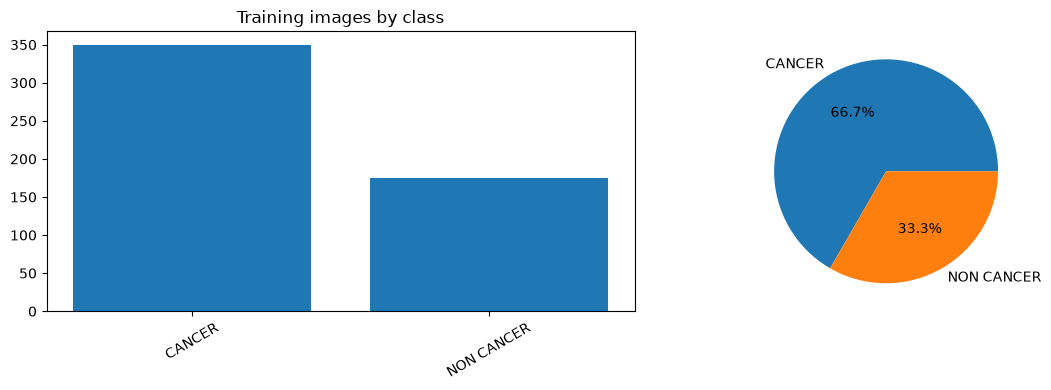

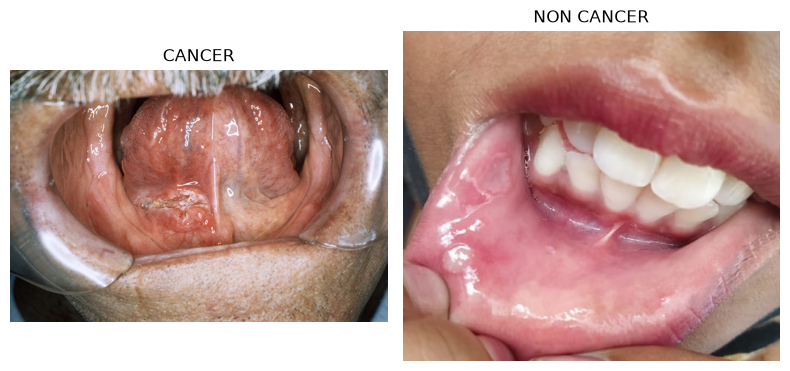

In [6]:
counts = [len(image_files(DATA_DIR / 'train' / name)) for name in class_names]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(class_names, counts)
axes[0].set_title('Training images by class')
axes[0].tick_params(axis='x', labelrotation=30)
axes[1].pie(counts, labels=class_names, autopct='%.1f%%')
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(4 * NUM_CLASSES, 4), squeeze=False)
for i, name in enumerate(class_names):
    with Image.open(random.choice(image_files(DATA_DIR / 'train' / name))) as img:
        axes[0, i].imshow(img.convert('RGB'))
    axes[0, i].set_title(name)
    axes[0, i].axis('off')
plt.tight_layout()
plt.show()


In [9]:
NUM_CLASSES

2

## Model and preprocessing
Augmentation runs only during training. Normalization stays inside the saved model so inference and fusion accept raw RGB images.

In [7]:
MODEL_NAME = 'efficientnetb0'
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal', seed=SEED),
    tf.keras.layers.RandomRotation(0.014, seed=SEED),
    tf.keras.layers.RandomTranslation(0.05, 0.05, seed=SEED),
    tf.keras.layers.RandomZoom(0.1, seed=SEED),
], name='augmentation')
inputs = tf.keras.Input(shape=(*TARGET_SIZE, 3), name='raw_rgb')
x = augmentation(inputs)
# EfficientNetB0 already includes preprocessing; keep raw RGB values here.
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False, weights=PRETRAINED_WEIGHTS, input_shape=(*TARGET_SIZE, 3))
base_model.trainable = False
x = base_model(x, training=False)
x = tf.keras.layers.Flatten()(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dense(1024, activation='relu')(x)
x = tf.keras.layers.Dropout(0.4)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dense(512, activation='relu')(x)
x = tf.keras.layers.Dropout(0.4)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dense(256, activation='relu')(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='class_probabilities')(x)
model = tf.keras.Model(inputs, outputs, name=MODEL_NAME)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
              loss='categorical_crossentropy',
              metrics=[tf.keras.metrics.CategoricalAccuracy(name='categorical_accuracy'),
                       tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')])
model.summary()




Model: "efficientnetb0"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 raw_rgb (InputLayer)        [(None, 100, 100, 3)]     0         
                                                                 
 augmentation (Sequential)   (None, 100, 100, 3)       0         
                                                                 
 efficientnetb0 (Functional  (None, 4, 4, 1280)        4049571   
 )                                                               
                                                                 
 flatten (Flatten)           (None, 20480)             0         
                                                                 
 batch_normalization (Batch  (None, 20480)             81920     
 Normalization)                                                  
                                                                 
 dense (Dense)               (None, 1024)         

In [8]:
train_labels = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in train_ds])
classes = np.arange(NUM_CLASSES)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=train_labels)
class_weight = {int(i): float(w) for i, w in zip(classes, weights)}
callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
             tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7)]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    callbacks=callbacks, class_weight=class_weight)


InvalidArgumentError: {{function_node __wrapped__IteratorGetNext_output_types_2_device_/job:localhost/replica:0/task:0/device:CPU:0}} Unknown image file format. One of JPEG, PNG, GIF, BMP required.
	 [[{{node decode_image/DecodeImage}}]] [Op:IteratorGetNext] name: 

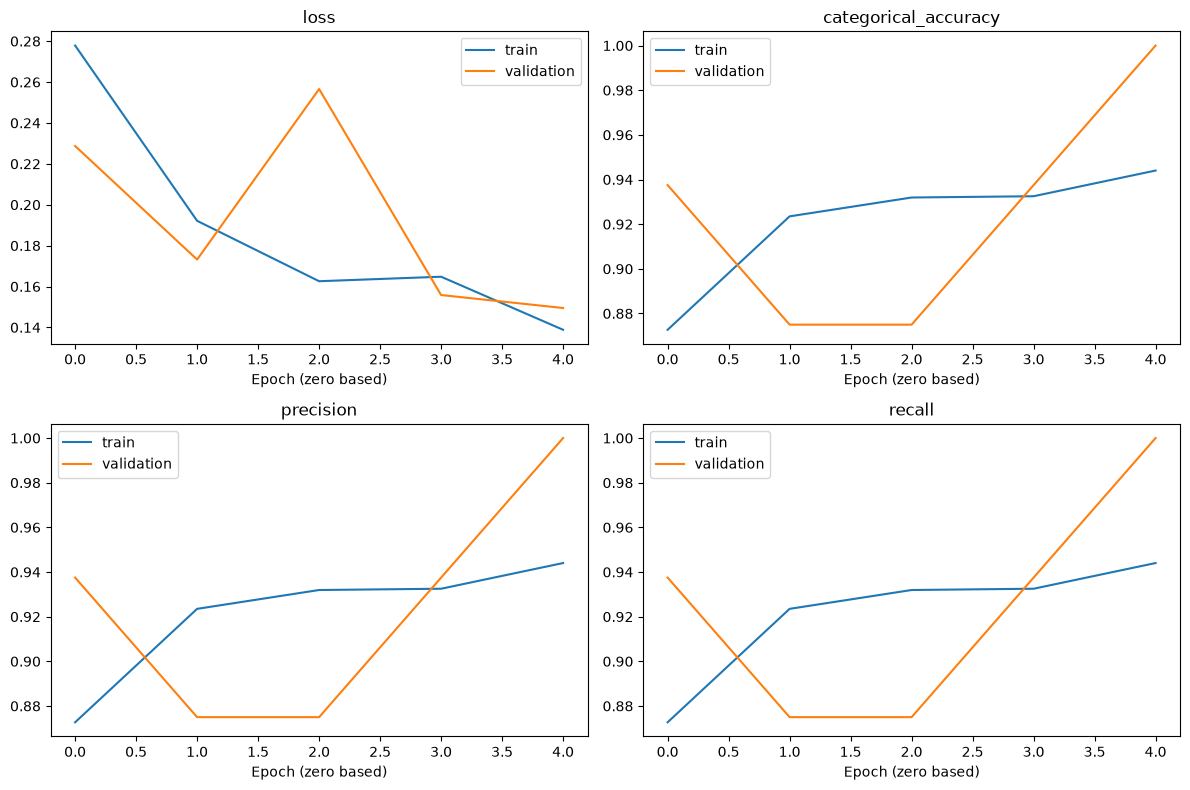

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, metric in zip(axes.flat, ['loss', 'categorical_accuracy', 'precision', 'recall']):
    ax.plot(history.history[metric], label='train')
    ax.plot(history.history['val_' + metric], label='validation')
    ax.set_title(metric)
    ax.set_xlabel('Epoch (zero based)')
    ax.legend()
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / f'{MODEL_NAME}_history.png', dpi=200)
plt.show()


39/39 [==============================] - 7s 173ms/step - loss: 0.2922 - categorical_accuracy: 0.8990 - precision: 0.8990 - recall: 0.8990
Test metrics: {'loss': 0.29221704602241516, 'categorical_accuracy': 0.8990384340286255, 'precision': 0.8990384340286255, 'recall': 0.8990384340286255}
39/39 [==============================] - 8s 149ms/step
              precision    recall  f1-score   support

      Cancer       0.90      0.94      0.92       390
      NORMAL       0.90      0.82      0.86       234

    accuracy                           0.90       624
   macro avg       0.90      0.88      0.89       624
weighted avg       0.90      0.90      0.90       624



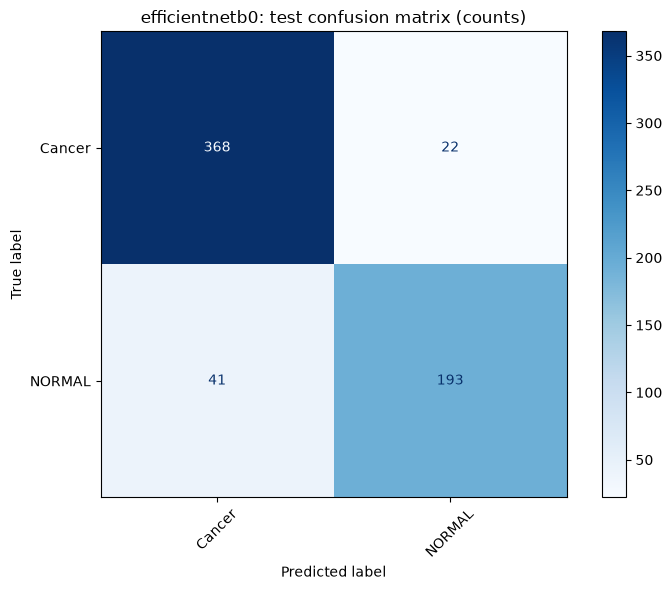

In [12]:
metrics = model.evaluate(test_ds, return_dict=True, verbose=1)
print('Test metrics:', metrics)
y_true = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in test_ds])
probabilities = model.predict(test_ds, verbose=1)
y_pred = probabilities.argmax(axis=1)
report = classification_report(y_true, y_pred, labels=range(NUM_CLASSES),
                               target_names=class_names, zero_division=0)
print(report)
(ARTIFACT_DIR / f'{MODEL_NAME}_report.txt').write_text(report)
(ARTIFACT_DIR / f'{MODEL_NAME}_metrics.json').write_text(json.dumps(metrics, indent=2))
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=range(NUM_CLASSES),
    display_labels=class_names, cmap='Blues', ax=ax, xticks_rotation=45)
ax.set_title(f'{MODEL_NAME}: test confusion matrix (counts)')
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / f'{MODEL_NAME}_confusion_matrix.png', dpi=200)
plt.show()


In [13]:
model_path = ARTIFACT_DIR / f'{MODEL_NAME}.keras'
model.save(model_path)
model.save_weights(ARTIFACT_DIR / f'{MODEL_NAME}.weights.h5')
metadata = {'class_names': class_names, 'class_indices': class_indices,
            'image_size': list(TARGET_SIZE), 'input_range': 'raw_rgb_0_255',
            'preprocessing_embedded': True, 'model_name': MODEL_NAME}
(ARTIFACT_DIR / f'{MODEL_NAME}_metadata.json').write_text(json.dumps(metadata, indent=2))
classifier = tf.keras.models.load_model(model_path, compile=False)
# Check that reloading preserved predictions on a real batch.
check_images, _ = next(iter(test_ds))
np.testing.assert_allclose(model(check_images, training=False).numpy(),
                           classifier(check_images, training=False).numpy(), rtol=1e-5, atol=1e-6)
print('Saved and reloaded:', model_path)


Saved and reloaded: model_outputs\efficientnetb0.keras


## Single-image prediction
Labels come from the training folders. These outputs are research classifications; probability values are not calibrated clinical confidence.

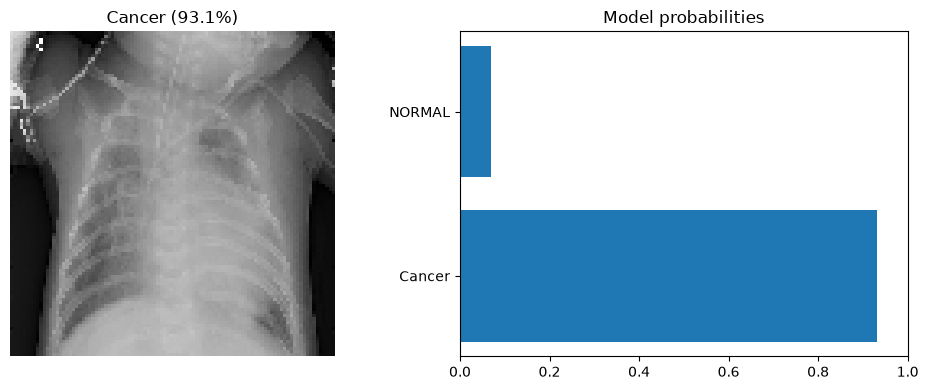

{'class': 'Cancer', 'confidence': 0.9313825964927673, 'probabilities': {'Cancer': 0.9313825964927673, 'NORMAL': 0.06861738115549088}}


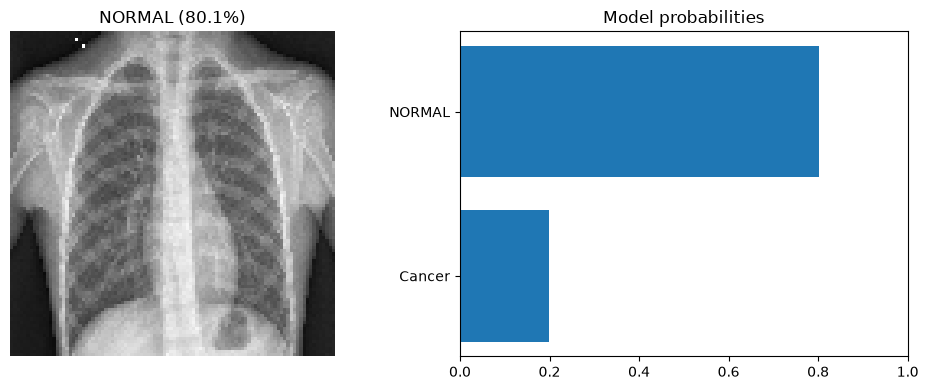

{'class': 'NORMAL', 'confidence': 0.8012529015541077, 'probabilities': {'Cancer': 0.19874708354473114, 'NORMAL': 0.8012529015541077}}


In [14]:
def predict(image_path, classifier=classifier):
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(image_path)
    img = tf.keras.utils.load_img(image_path, color_mode='rgb', target_size=TARGET_SIZE,
                                 interpolation='nearest')
    x = tf.keras.utils.img_to_array(img)[None, ...]  # Raw pixels, no extra /255.
    scores = classifier.predict(x, verbose=0)[0]
    index = int(np.argmax(scores))
    result = {'class': class_names[index], 'confidence': float(scores[index]),
              'probabilities': dict(zip(class_names, map(float, scores)))}
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(img)
    axes[0].set_title(f"{result['class']} ({result['confidence']:.1%})")
    axes[0].axis('off')
    axes[1].barh(class_names, scores)
    axes[1].set_xlim(0, 1)
    axes[1].set_title('Model probabilities')
    plt.tight_layout()
    plt.show()
    print(result)
    return result
# Replace with your own file path, or run one available test image per class.
for name in class_names:
    predict(image_files(DATA_DIR / 'test' / name)[0])
